<a href="https://colab.research.google.com/github/KrithikChidM/PrmlLab/blob/main/Lab6/code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Class 1: total distortion = 7578.72, mean = 1.8947
  centroids:
[[ 0.055 -0.233]
 [ 1.006  3.402]
 [-1.171 -3.669]]
  cluster sizes: [1335  860 1805]
Class 2: total distortion = 7741.34, mean = 1.9353
  centroids:
[[ 2.979 -3.523]
 [ 3.929 -0.05 ]
 [ 4.93   3.409]]
  cluster sizes: [1999 1168  833]

=== Distortion-based classification on 20% test data ===
Confusion matrix (rows = true, cols = predicted):
[[968  32]
 [ 33 967]]
Overall accuracy: 96.75%
Class 1 accuracy: 96.80%
Class 2 accuracy: 96.70%
Mean test distortion (true class):  1.8054
Mean test distortion (other class): 16.8938


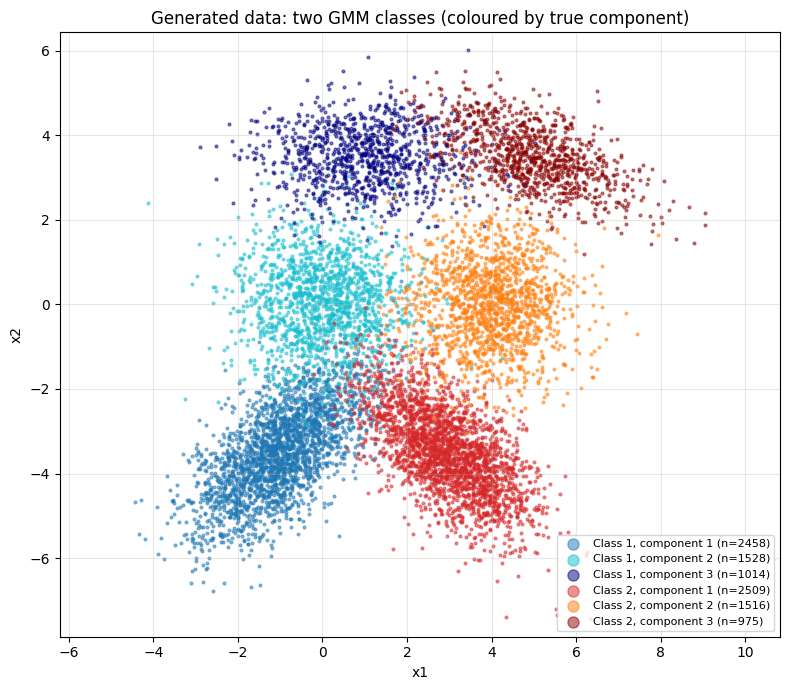

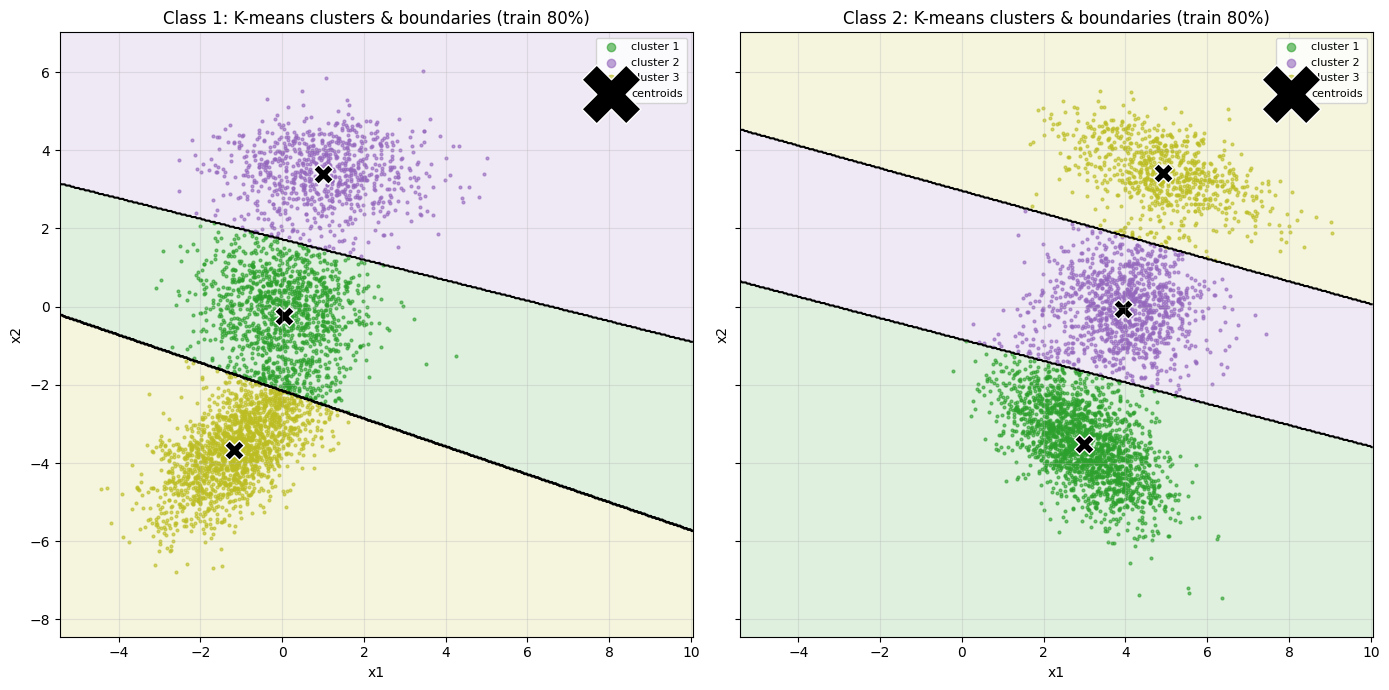

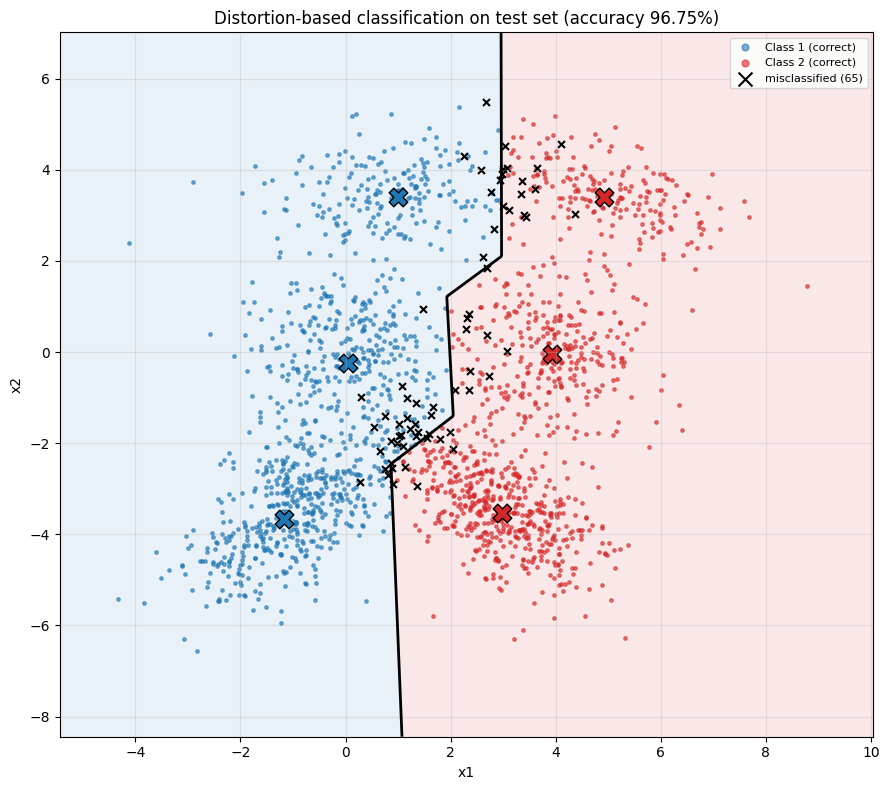

In [3]:
import math
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# ----------------------------------------------------------------------
# Hyper-parameters
# ----------------------------------------------------------------------
n = 5000
K = 3
weights = np.array([0.5, 0.3, 0.2])

means = np.array([[-1.0, -3.5], [0.0, 0.0], [1.0, 3.5]])
means_2 = means + np.array([4.0, 0.0])
class_means = [means, means_2]

covariances = [
    np.array([[1.0, 0.6], [0.6, 1.0]]),  # bottom: full
    np.eye(2),                           # middle: isotropic
    np.diag([1.5, 0.5])                  # top: diagonal
]

covariances_2 = [
    np.array([[1.0, -0.6], [-0.6, 1.0]]),
    np.eye(2),
    np.array([[1.5, -0.5], [-0.5, 0.5]])
]
class_covariances = [covariances, covariances_2]


# ----------------------------------------------------------------------
# Box-Muller: uniform -> standard normal
# ----------------------------------------------------------------------
def box_muller():
    """One pair of independent N(0, 1) samples from two uniforms."""
    u1 = max(np.random.uniform(0.0, 1.0), 1e-12)   # avoid log(0)
    u2 = np.random.uniform(0.0, 1.0)
    r = math.sqrt(-2.0 * math.log(u1))
    theta = 2.0 * math.pi * u2
    return r * math.cos(theta), r * math.sin(theta)


def generate_component(mean, C):
    z1, z2 = box_muller()
    a, b = C[0]
    c, d = C[1]
    l11 = math.sqrt(a)
    l21 = c / l11
    l22 = math.sqrt(max(d - l21 * l21, 1e-12))
    x1 = mean[0] + l11 * z1
    x2 = mean[1] + l21 * z1 + l22 * z2
    return [x1, x2]


def sample_gmm(n, weights, mus, covs):
    """Draw n samples from a GMM. Returns X (n,2) and component labels (n,)."""
    cum = np.cumsum(weights)
    X = np.zeros((n, 2))
    comp = np.zeros(n, dtype=int)
    for i in range(n):
        k = min(int(np.searchsorted(cum, np.random.uniform(0.0, 1.0))), len(weights) - 1)
        comp[i] = k
        X[i] = generate_component(mus[k], covs[k])
    return X, comp


# ----------------------------------------------------------------------
# K-means from scratch
# ----------------------------------------------------------------------
def sq_dists(X, C):
    """Squared Euclidean distance between every row of X and every row of C."""
    return ((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2)


def kmeans_once(X, K, max_iter=300, tol=1e-6):
    # k-means++ style initialisation
    centroids = [X[np.random.randint(len(X))]]
    for _ in range(1, K):
        d2 = sq_dists(X, np.array(centroids)).min(axis=1)
        cum = np.cumsum(d2 / d2.sum())
        centroids.append(X[min(np.searchsorted(cum, np.random.uniform()), len(X) - 1)])
    centroids = np.array(centroids)

    for _ in range(max_iter):
        labels = sq_dists(X, centroids).argmin(axis=1)
        new_c = centroids.copy()
        for k in range(K):
            pts = X[labels == k]
            if len(pts) > 0:                 # keep old centroid if cluster empties
                new_c[k] = pts.mean(axis=0)
        shift = np.abs(new_c - centroids).max()
        centroids = new_c
        if shift < tol:
            break

    d = sq_dists(X, centroids)
    return centroids, d.argmin(axis=1), d.min(axis=1).sum()


def kmeans(X, K, n_init=10):
    """Several restarts; keep the lowest-distortion solution."""
    best = None
    for _ in range(n_init):
        res = kmeans_once(X, K)
        if best is None or res[2] < best[2]:
            best = res
    return best


# ----------------------------------------------------------------------
# 1) Generate data for two classes
# ----------------------------------------------------------------------
X_cls, comp_cls = [], []
for c in range(2):
    X, comp = sample_gmm(n, weights, class_means[c], class_covariances[c])
    X_cls.append(X)
    comp_cls.append(comp)

comp_colors = [["tab:blue", "tab:cyan", "navy"],
               ["tab:red", "tab:orange", "darkred"]]
fig, ax = plt.subplots(figsize=(8, 7))
for c in range(2):
    for k in range(K):
        m = comp_cls[c] == k
        ax.scatter(X_cls[c][m, 0], X_cls[c][m, 1], s=4, alpha=0.5,
                   color=comp_colors[c][k],
                   label=f"Class {c+1}, component {k+1} (n={m.sum()})")
ax.set_title("Generated data: two GMM classes (coloured by true component)")
ax.set_xlabel("x1"); ax.set_ylabel("x2")
ax.legend(markerscale=4, fontsize=8); ax.grid(alpha=0.3); ax.axis("equal")
plt.tight_layout()
plt.savefig("fig1_generated_data.png", dpi=150)

# ----------------------------------------------------------------------
# 2) 80-20 split per class
# ----------------------------------------------------------------------
X_train, X_test = [], []
n_tr = int(0.8 * n)
for c in range(2):
    perm = np.random.permutation(n)
    X_train.append(X_cls[c][perm[:n_tr]])
    X_test.append(X_cls[c][perm[n_tr:]])

# ----------------------------------------------------------------------
# 3) K-means on the 80% of each class
# ----------------------------------------------------------------------
centroids, tr_labels = [], []
for c in range(2):
    C, lab, dist = kmeans(X_train[c], K)
    centroids.append(C)
    tr_labels.append(lab)
    print(f"Class {c+1}: total distortion = {dist:.2f}, "
          f"mean = {dist / len(X_train[c]):.4f}")
    print(f"  centroids:\n{np.round(C, 3)}")
    print(f"  cluster sizes: {np.bincount(lab, minlength=K)}")

# ----------------------------------------------------------------------
# 4) Cluster boundaries for each class
# ----------------------------------------------------------------------
all_pts = np.vstack(X_train + X_test)
x_min, x_max = all_pts[:, 0].min() - 1, all_pts[:, 0].max() + 1
y_min, y_max = all_pts[:, 1].min() - 1, all_pts[:, 1].max() + 1
gx, gy = np.meshgrid(np.linspace(x_min, x_max, 500),
                     np.linspace(y_min, y_max, 500))
grid = np.stack([gx.ravel(), gy.ravel()], axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharex=True, sharey=True)
cluster_colors = ["tab:green", "tab:purple", "tab:olive"]
for c in range(2):
    ax = axes[c]
    cell = sq_dists(grid, centroids[c]).argmin(axis=1).reshape(gx.shape)
    ax.contourf(gx, gy, cell, levels=[-0.5, 0.5, 1.5, 2.5],
                colors=cluster_colors, alpha=0.15)
    ax.contour(gx, gy, cell, levels=[0.5, 1.5], colors="k", linewidths=1.5)
    for k in range(K):
        m = tr_labels[c] == k
        ax.scatter(X_train[c][m, 0], X_train[c][m, 1], s=4, alpha=0.6,
                   color=cluster_colors[k], label=f"cluster {k+1}")
    ax.scatter(centroids[c][:, 0], centroids[c][:, 1], marker="X", s=200,
               c="k", edgecolors="w", label="centroids")
    ax.set_title(f"Class {c+1}: K-means clusters & boundaries (train 80%)")
    ax.set_xlabel("x1"); ax.set_ylabel("x2")
    ax.legend(markerscale=3, fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("fig2_kmeans_boundaries.png", dpi=150)

# ----------------------------------------------------------------------
# 5) Classify the 20% by distortion
#    D_c(x) = min_k ||x - mu_{c,k}||^2 ;  predicted class = argmin_c D_c(x)
# ----------------------------------------------------------------------
def class_distortions(X):
    return np.stack([sq_dists(X, centroids[c]).min(axis=1) for c in range(2)], axis=1)


X_te = np.vstack(X_test)
y_te = np.concatenate([np.zeros(len(X_test[0]), dtype=int),
                       np.ones(len(X_test[1]), dtype=int)])
D = class_distortions(X_te)
y_pred = D.argmin(axis=1)

conf = np.zeros((2, 2), dtype=int)
for t, p in zip(y_te, y_pred):
    conf[t, p] += 1
acc = (y_pred == y_te).mean()

print("\n=== Distortion-based classification on 20% test data ===")
print("Confusion matrix (rows = true, cols = predicted):")
print(conf)
print(f"Overall accuracy: {acc * 100:.2f}%")
for c in range(2):
    print(f"Class {c+1} accuracy: {conf[c, c] / conf[c].sum() * 100:.2f}%")
print(f"Mean test distortion (true class):  {D[np.arange(len(y_te)), y_te].mean():.4f}")
print(f"Mean test distortion (other class): {D[np.arange(len(y_te)), 1 - y_te].mean():.4f}")

Dg = class_distortions(grid)
diff = (Dg[:, 0] - Dg[:, 1]).reshape(gx.shape)

fig, ax = plt.subplots(figsize=(9, 8))
ax.contourf(gx, gy, diff, levels=[-1e9, 0, 1e9],
            colors=["tab:blue", "tab:red"], alpha=0.10)
ax.contour(gx, gy, diff, levels=[0], colors="k", linewidths=2)
correct = y_pred == y_te
for c, col in enumerate(["tab:blue", "tab:red"]):
    m = (y_te == c) & correct
    ax.scatter(X_te[m, 0], X_te[m, 1], s=6, color=col, alpha=0.6,
               label=f"Class {c+1} (correct)")
ax.scatter(X_te[~correct, 0], X_te[~correct, 1], s=25, marker="x",
           color="k", label=f"misclassified ({(~correct).sum()})")
for c, col in enumerate(["tab:blue", "tab:red"]):
    ax.scatter(centroids[c][:, 0], centroids[c][:, 1], marker="X", s=180,
               color=col, edgecolors="k")
ax.set_title(f"Distortion-based classification on test set (accuracy {acc * 100:.2f}%)")
ax.set_xlabel("x1"); ax.set_ylabel("x2")
ax.legend(markerscale=2, fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("fig3_classification.png", dpi=150)

plt.show()

In [123]:
# --- Fig 1: generated data, coloured by generating component ---
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)
for c in range(2):
    for k in range(K):
        m = comps[c] == k
        axes[c].scatter(data[c][m, 0], data[c][m, 1], s=4, alpha=0.5,
                        color=comp_colors[c][k], label=comp_names[k])
        axes[2].scatter(data[c][m, 0], data[c][m, 1], s=4, alpha=0.4,
                        color=comp_colors[c][k])
    axes[c].plot(*class_means[c].T, 'k*', ms=12)
    axes[c].set_title(f"Class {c+1}: generated data (by mixture component)")
    axes[c].legend(markerscale=3)
axes[2].set_title("Both classes")
for a in axes:
    a.set_xlabel("x1"); a.grid(alpha=0.3)
axes[0].set_ylabel("x2")
plt.tight_layout()
plt.show()

In [ ]:
# --- Fig 2: K-means clusters + cluster boundaries per class (80% train data) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
for c in range(2):
    ax = axes[c]
    zgrid = sq_dists(grid, centroids[c]).argmin(axis=1).reshape(xx.shape)
    cols = comp_colors[c]
    ax.contourf(xx, yy, zgrid, levels=[-0.5, 0.5, 1.5, 2.5], colors=cols, alpha=0.12)
    ax.contour(xx, yy, zgrid, levels=[0.5, 1.5], colors='k', linewidths=1.5)
    for k in range(K):
        m = train_labels[c] == k
        ax.scatter(X_train[c][m, 0], X_train[c][m, 1], s=4, color=cols[k],
                   alpha=0.6, label=f"cluster {k+1}")
    ax.plot(*centroids[c].T, 'k*', ms=14, mec='w')
    ax.set_title(f"Class {c+1}: K-means (K={K}) on 80% train, boundaries in black")
    ax.set_xlabel("x1"); ax.grid(alpha=0.3); ax.legend(markerscale=3)
axes[0].set_ylabel("x2")
plt.tight_layout()
plt.show()

In [ ]:
# --- Fig 3: class decision boundary (min-distortion rule) + test points ---
fig, ax = plt.subplots(figsize=(9, 7))
zc = classify(grid, centroids).reshape(xx.shape)
ax.contourf(xx, yy, zc, levels=[-0.5, 0.5, 1.5], colors=['tab:red', 'tab:blue'], alpha=0.12)
ax.contour(xx, yy, zc, levels=[0.5], colors='k', linewidths=2)
correct = pred == yt
for c, col in enumerate(['tab:red', 'tab:blue']):
    m = (yt == c) & correct
    ax.scatter(Xt[m, 0], Xt[m, 1], s=6, color=col, alpha=0.6, label=f"Class {c+1} (correct)")
ax.scatter(Xt[~correct, 0], Xt[~correct, 1], s=25, marker='x', color='k',
           label=f"misclassified ({(~correct).sum()})")
for c in range(2):
    ax.plot(*centroids[c].T, '*', ms=14, mec='w', color=['darkred', 'darkblue'][c])
ax.set_title(f"Distortion-based classification of 20% test data (acc = {acc*100:.2f}%)")
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.grid(alpha=0.3); ax.legend(markerscale=2)
plt.tight_layout()
plt.show()

#A6D

In [ ]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt

random.seed(42)

N = 1500
K = 3
num_classes = 2
weights = [0.3, 0.4, 0.3]

In [ ]:
means = [
    [[-5, -2], [-2, 3], [1, -2]],
    [[4, 3], [7, -1], [9, 4]]
]

scales = [0.8, 1.0, 0.9]

In [ ]:
def uniform():
    return max(random.random(), 1e-12)

def box_muller():
    u1 = uniform()
    u2 = uniform()
    r = math.sqrt(-2 * math.log(u1))
    theta = 2 * math.pi * u2
    z1 = r * math.cos(theta)
    z2 = r * math.sin(theta)
    return z1, z2

In [ ]:
def gaussian_density(x, mean, C):
    a, b = C[0]
    c, d = C[1]
    det = a*d - b*c

    inv = [
        [d/det, -b/det],
        [-c/det, a/det]
    ]

    dx = x[0] - mean[0]
    dy = x[1] - mean[1]
    q = dx*(inv[0][0]*dx + inv[0][1]*dy) + \
        dy*(inv[1][0]*dx + inv[1][1]*dy)

    return math.exp(-0.5*q) / (2*math.pi*math.sqrt(det))

# Example: standard 2D normal density at the origin
x = [0, 0]
mu = [0, 0]
C = [[1, 0], [0, 1]]
print(gaussian_density(x, mu, C))

0.15915494309189535


In [ ]:
def gmm_density(x, means, covs, weights):
    p = 0
    for i in range(len(weights)):
        p += weights[i] * gaussian_density(x, means[i], covs[i])
    return p

In [ ]:
def generate_component(mean, C):
    z1, z2 = box_muller()
    a, b = C[0]
    c, d = C[1]
    l11 = math.sqrt(a)
    l21 = c / l11
    l22 = math.sqrt(max(d - l21*l21, 1e-12))
    x1 = mean[0] + l11*z1
    x2 = mean[1] + l21*z1 + l22*z2
    return [x1, x2]

In [ ]:
def generate_gmm_data(means, covs, weights, n):
    X = []
    for _ in range(n):
        u = uniform()
        if u < weights[0]:
            k = 0
        elif u < weights[0] + weights[1]:
            k = 1
        else:
            k = 2
        X.append(generate_component(means[k], covs[k]))
    return np.array(X)

In [ ]:
def make_covariances(kind, scales):
    covs = []
    for s in scales:
        if kind == "Spherical":
            C = [[s*s, 0], [0, s*s]]
        elif kind == "Diagonal":
            C = [[s*s, 0], [0, (0.7*s)**2]]
        else:
            C = [[s*s, 0.6*s*s], [0.6*s*s, 1.4*s*s]]
        covs.append(C)
    return covs

In [ ]:
covariance_types = ["Spherical", "Diagonal", "Full"]
class0 = []
class0_d = []
class1 = []
class1_d = []

i = 0
for kind in covariance_types:
    covs = make_covariances(kind, scales)

    print("\nCovariance Type:", kind)

    for cls in range(num_classes):
        X = generate_gmm_data(means[cls], covs, weights, N)

        densities = [
            gmm_density(x, means[cls], covs, weights)
            for x in X
        ]

        print("\nClass", cls + 1)
        print("GMM density at sample point:",
              gmm_density(X[0], means[cls], covs, weights))
        print("Mean GMM density: {:.8f}".format(
            sum(densities) / len(densities)
        ))
        print("Minimum GMM density: {:.8e}".format(min(densities)))
        print("Maximum GMM density: {:.8e}".format(max(densities)))
        if i%2 == 0:
            class0.append(X)
            class0_d.append(densities)
        else:
            class1.append(X)
            class1_d.append(densities)
        i += 1


Covariance Type: Spherical

Class 1
GMM density at sample point: 0.0015922341296595495
Mean GMM density: 0.03253242
Minimum GMM density: 1.08044229e-05
Maximum GMM density: 7.45526046e-02

Class 2
GMM density at sample point: 0.0028678604121236445
Mean GMM density: 0.03205502
Minimum GMM density: 5.04369786e-06
Maximum GMM density: 7.45088479e-02

Covariance Type: Diagonal

Class 1
GMM density at sample point: 0.07748818514159989
Mean GMM density: 0.04562166
Minimum GMM density: 2.72229967e-04
Maximum GMM density: 1.06321752e-01

Class 2
GMM density at sample point: 0.09955591171809469
Mean GMM density: 0.04660568
Minimum GMM density: 8.44993811e-06
Maximum GMM density: 1.06379273e-01

Covariance Type: Full

Class 1
GMM density at sample point: 0.044369429520393584
Mean GMM density: 0.03181247
Minimum GMM density: 4.44587586e-05
Maximum GMM density: 7.31123591e-02

Class 2
GMM density at sample point: 0.043920549687880985
Mean GMM density: 0.03258092
Minimum GMM density: 3.90906944e-0

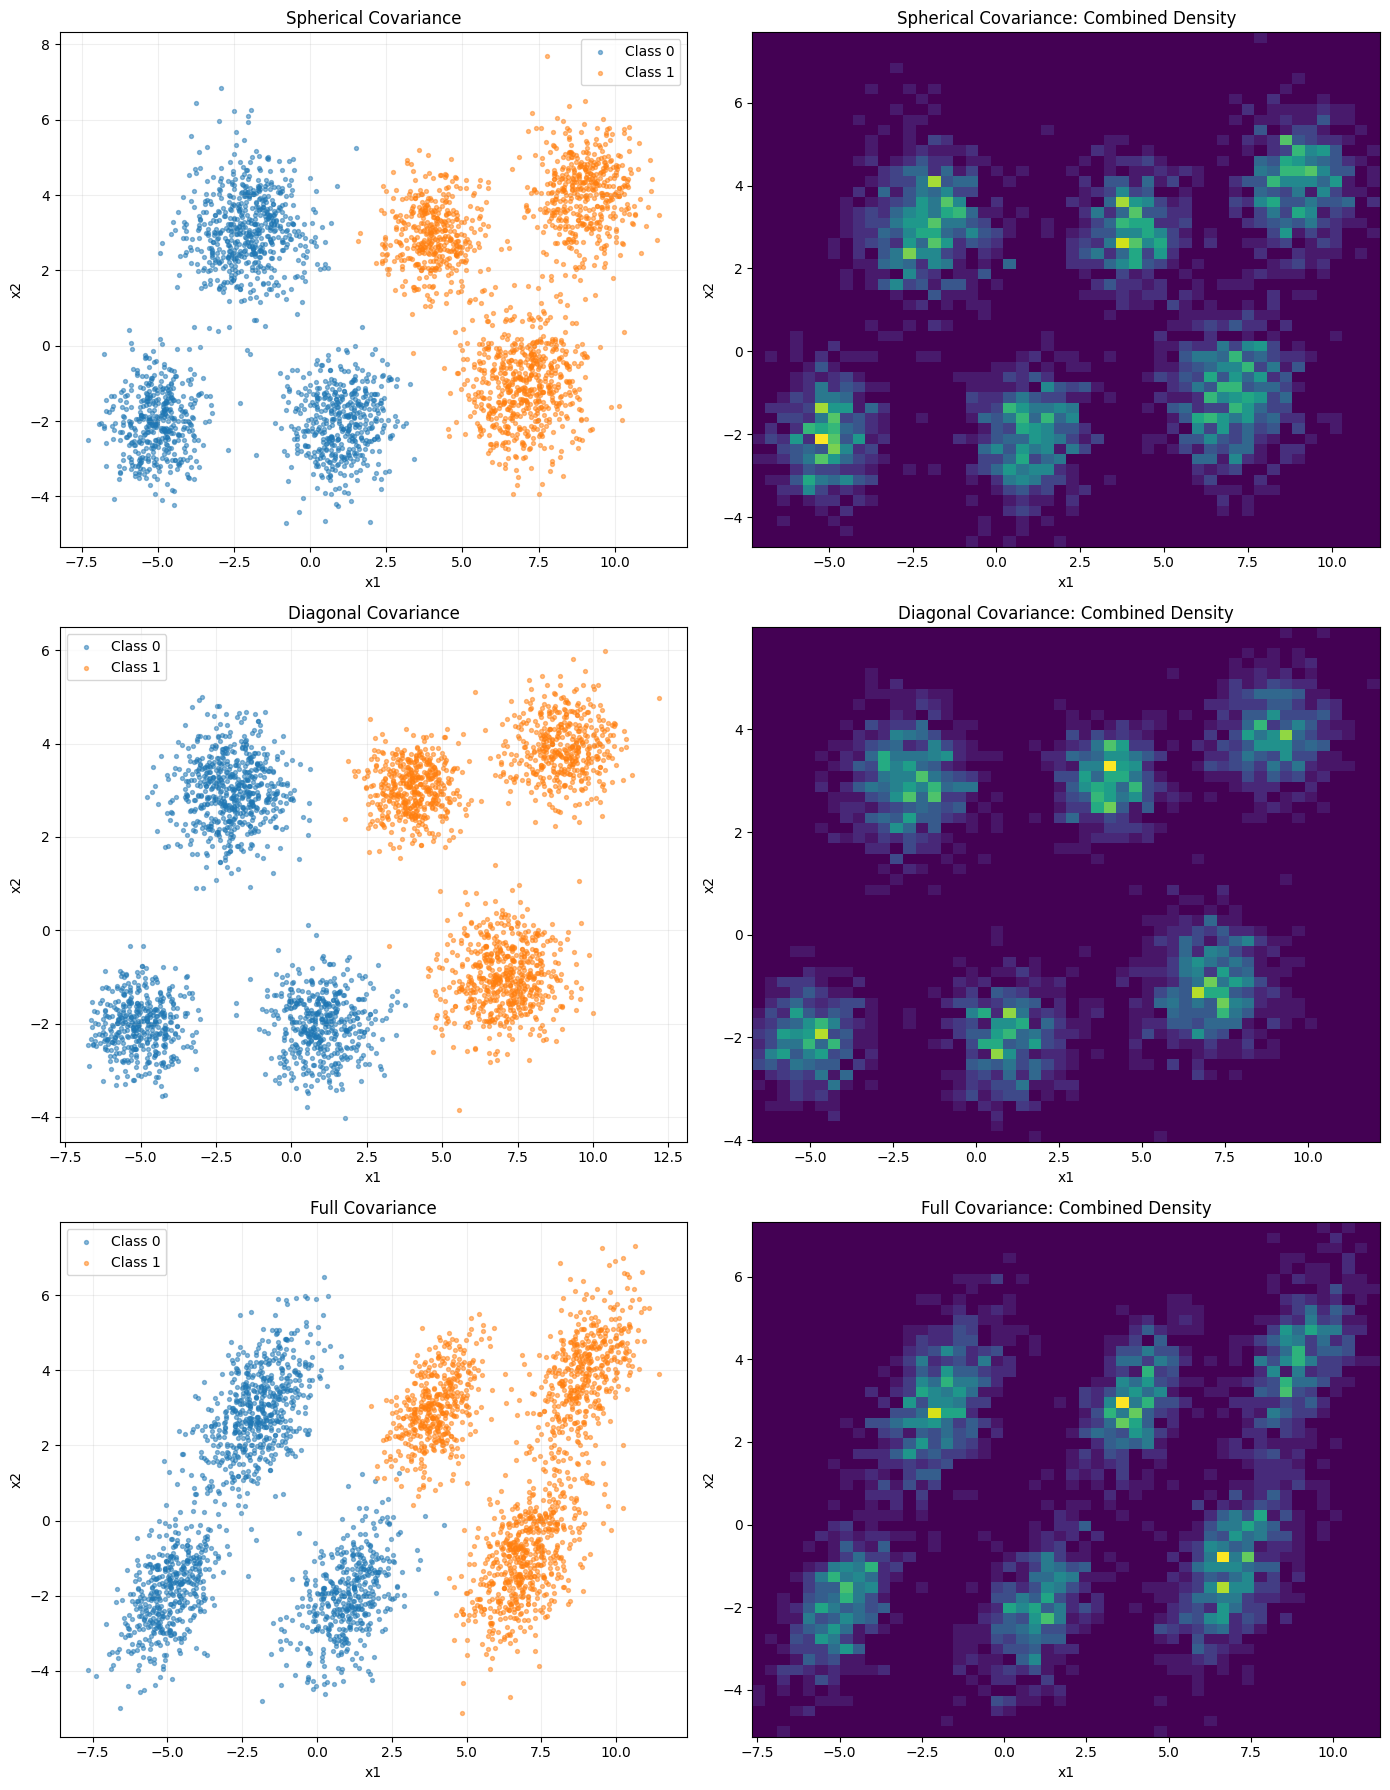

In [ ]:
covariance_types = ["Spherical", "Diagonal", "Full"]

fig, axes = plt.subplots(3, 2, figsize=(14, 18))

for i in range(3):
    X0 = class0[i]
    X1 = class1[i]

    axes[i, 0].scatter(X0[:, 0], X0[:, 1], s=8, alpha=0.5, label="Class 0")
    axes[i, 0].scatter(X1[:, 0], X1[:, 1], s=8, alpha=0.5, label="Class 1")
    axes[i, 0].set_title(covariance_types[i] + " Covariance")
    axes[i, 0].set_xlabel("x1")
    axes[i, 0].set_ylabel("x2")
    axes[i, 0].legend()
    axes[i, 0].grid(alpha=0.2)

    x_values = np.vstack([X0, X1])
    axes[i, 1].hist2d(x_values[:, 0], x_values[:, 1], bins=50)
    axes[i, 1].set_title(covariance_types[i] + " Covariance: Combined Density")
    axes[i, 1].set_xlabel("x1")
    axes[i, 1].set_ylabel("x2")

plt.tight_layout()
plt.show()

In [ ]:

def split_train_test(X, ratio=0.8):
    indices = list(range(len(X)))
    random.shuffle(indices)
    cut = int(ratio * len(X))
    return X[indices[:cut]], X[indices[cut:]]

def fit_gmm_em(X, K=3, covariance_type="Full", max_iter=100):
    n, d = X.shape
    chosen = random.sample(range(n), K)
    mu = X[chosen].copy()
    weights_gmm = np.ones(K) / K
    covs = []

    for j in range(K):
        if covariance_type == "Spherical":
            covs.append(np.eye(d) * np.var(X))
        elif covariance_type == "Diagonal":
            covs.append(np.diag(np.maximum(np.var(X, axis=0), 1e-4)))
        else:
            covs.append(np.cov(X.T) + np.eye(d) * 1e-4)

    for iteration in range(max_iter):
        resp = np.zeros((n, K))

        for i in range(n):
            for j in range(K):
                resp[i, j] = weights_gmm[j] * gaussian_density(
                    X[i], mu[j], covs[j]
                )

            total = resp[i].sum()
            if total > 1e-300:
                resp[i] /= total
            else:
                resp[i] = 1.0 / K

        Nk = resp.sum(axis=0)
        Nk = np.maximum(Nk, 1e-8)
        new_weights = Nk / n
        new_mu = (resp.T @ X) / Nk[:, None]
        new_covs = []

        for j in range(K):
            diff = X - new_mu[j]
            weighted_cov = (diff.T @ (diff * resp[:, j, None])) / Nk[j]

            if covariance_type == "Spherical":
                variance = np.trace(weighted_cov) / d
                C = np.eye(d) * max(variance, 1e-4)
            elif covariance_type == "Diagonal":
                C = np.diag(np.maximum(np.diag(weighted_cov), 1e-4))
            else:
                C = weighted_cov + np.eye(d) * 1e-4

            new_covs.append(C)

        if np.allclose(mu, new_mu, atol=1e-4):
            mu = new_mu
            weights_gmm = new_weights
            covs = new_covs
            break

        mu = new_mu
        weights_gmm = new_weights
        covs = new_covs

    return mu, covs, weights_gmm

def predict_gmm(X, model):
    mu, covs, weights_gmm = model
    predictions = []

    for x in X:
        component_densities = [
            weights_gmm[j] * gaussian_density(x, mu[j], covs[j])
            for j in range(len(weights_gmm))
        ]
        predictions.append(max(sum(component_densities), 1e-300))

    return np.array(predictions)

def confusion_matrix_manual(y_true, y_pred):
    cm = np.zeros((2, 2), dtype=int)

    for actual, predicted in zip(y_true, y_pred):
        cm[actual, predicted] += 1

    return cm

covariance_types = ["Spherical", "Diagonal", "Full"]
gmm_results = {}

for i, kind in enumerate(covariance_types):
    X0_train, X0_test = split_train_test(class0[i])
    X1_train, X1_test = split_train_test(class1[i])

    model0 = fit_gmm_em(X0_train, K=3, covariance_type=kind)
    model1 = fit_gmm_em(X1_train, K=3, covariance_type=kind)

    X_test = np.vstack([X0_test, X1_test])
    y_true = np.concatenate([
        np.zeros(len(X0_test), dtype=int),
        np.ones(len(X1_test), dtype=int)
    ])

    density0 = predict_gmm(X_test, model0)
    density1 = predict_gmm(X_test, model1)

    y_pred = (density1 > density0).astype(int)

    cm = confusion_matrix_manual(y_true, y_pred)
    accuracy = np.trace(cm) / np.sum(cm) * 100

    gmm_results[kind] = {
        "model0": model0,
        "model1": model1,
        "confusion_matrix": cm,
        "accuracy": accuracy,
        "y_true": y_true,
        "y_pred": y_pred
    }

    print("\n", "=" * 40)
    print("Covariance Type:", kind)
    print("Class 0 training samples:", len(X0_train))
    print("Class 0 testing samples:", len(X0_test))
    print("Class 1 training samples:", len(X1_train))
    print("Class 1 testing samples:", len(X1_test))
    print("\nConfusion Matrix:")
    print(cm)
    print("Rows = Actual [Class 0, Class 1]")
    print("Columns = Predicted [Class 0, Class 1]")
    print("Classification Accuracy: {:.2f}%".format(accuracy))


Covariance Type: Spherical
Class 0 training samples: 1200
Class 0 testing samples: 300
Class 1 training samples: 1200
Class 1 testing samples: 300

Confusion Matrix:
[[300   0]
 [  0 300]]
Rows = Actual [Class 0, Class 1]
Columns = Predicted [Class 0, Class 1]
Classification Accuracy: 100.00%

Covariance Type: Diagonal
Class 0 training samples: 1200
Class 0 testing samples: 300
Class 1 training samples: 1200
Class 1 testing samples: 300

Confusion Matrix:
[[300   0]
 [  1 299]]
Rows = Actual [Class 0, Class 1]
Columns = Predicted [Class 0, Class 1]
Classification Accuracy: 99.83%

Covariance Type: Full
Class 0 training samples: 1200
Class 0 testing samples: 300
Class 1 training samples: 1200
Class 1 testing samples: 300

Confusion Matrix:
[[298   2]
 [  0 300]]
Rows = Actual [Class 0, Class 1]
Columns = Predicted [Class 0, Class 1]
Classification Accuracy: 99.67%
